# Pertemuan 2 — Preprocessing Data 1
### Praktik: eksplorasi data, data cleaning, dan kualitas data

<a href="https://colab.research.google.com/github/[username]/[nama-repo]/blob/main/pertemuan-02/02_Preprocessing_Data_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

> Ganti `[username]` dan `[nama-repo]` pada tautan di atas (dan pada `URL_DATA` di bagian 2) dengan alamat repositori GitHub kelas.

**Setelah menyelesaikan notebook ini, kamu bisa:**

1. Menjelajahi dataset baru untuk menemukan sendiri masalah kualitasnya.
2. Menilai kualitas data dari empat sisi: lengkap, valid, konsisten, dan unik.
3. Memperbaiki tipe data yang salah.
4. Menemukan duplikat, termasuk yang tidak terlihat dengan cara biasa.
5. Merapikan kategori yang tidak konsisten.
6. Membedakan outlier yang merupakan **kesalahan** dengan outlier yang **nyata**.
7. Menangani nilai kosong dan memilih antara mean dan median.
8. Mendokumentasikan setiap keputusan pembersihan.

**Dataset:** Customer Personality Analysis (Kaggle), data pelanggan tim marketing. Penjelasan kolomnya ada di `README MEET 2.md`. Dataset ini akan kita pakai **sampai Pertemuan 7**.

**Perkiraan waktu:** 60–70 menit.

---
## 1. Business case: laporan profil pelanggan yang janggal

Sekarang **Juli 2014**. Kamu adalah data analyst di **tim marketing** *RetailKu* (perusahaan fiktif), sebuah perusahaan ritel yang menjual kebutuhan rumah tangga lewat toko, situs web, dan katalog. Tim ini mengelola data pelanggan untuk kampanye promosi.

Besok manajer marketing akan presentasi ke direksi untuk merencanakan kampanye berikutnya. Seorang anak magang sudah membuat laporan profil pelanggan langsung dari data mentah:

> 📄 *"Kita punya **2.240 pelanggan**, berumur **18 sampai 121 tahun**, dengan **8 jenis status pernikahan**."*

Manajer membaca laporan itu dan mengernyit:

> *"Umur 121 tahun? Status pernikahan ada delapan? Tolong cek data ini sebelum saya bawa ke direksi besok."*

| Pertanyaan bisnis | Pertanyaan data |
|---|---|
| Berapa jumlah pelanggan kita sebenarnya? | Adakah pelanggan yang tercatat lebih dari sekali? |
| Benarkah ada pelanggan berumur 121 tahun? | Nilai mana yang tidak masuk akal? |
| Bisakah angka pendapatan dipercaya? | Adakah nilai kosong atau nilai ekstrem? |
| Kenapa status pernikahan ada delapan? | Adakah label yang tidak konsisten atau tidak valid? |

Kamu belum pernah melihat data ini. Jadi urutan kerjamu:

1. **Jelajahi** datanya dan catat semua yang terlihat aneh (bagian 3).
2. **Bersihkan** satu per satu, dan catat setiap keputusan (bagian 5–11).
3. **Laporkan** angka sebelum dan sesudah ke manajer (bagian 12).

---
## 2. Menyiapkan alat dan mengambil data

In [2]:
import os
import urllib.request

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

WARNA = "#2B6F7E"        # warna utama grafik
WARNA_SOROT = "#B4501F"  # warna untuk menyorot

In [6]:
# Hubungkan Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Tentukan path tempat Anda menyimpan file di Google Drive
FILE_DATA = '/content/drive/MyDrive/UNIPA 2026/Meet 2/marketing_campaign.csv'

Mounted at /content/drive


### Membaca file

File berakhiran `.csv`, jadi kita baca dengan `pd.read_csv()`. Seperti biasa, langsung cek `shape` dan `head()`.

In [27]:
coba = pd.read_csv(FILE_DATA)
print("Ukuran:", coba.shape)
coba.head(3)

Ukuran: (2240, 1)


,ID\tYear_Birth\tEducation\tMarital_Status\tIncome\tKidhome\tTeenhome\tDt_Customer\tRecency\tMntWines\tMntFruits\tMntMeatProducts\tMntFishProducts\tMntSweetProducts\tMntGoldProds\tNumDealsPurchases\tNumWebPurchases\tNumCatalogPurchases\tNumStorePurchases\tNumWebVisitsMonth\tAcceptedCmp3\tAcceptedCmp4\tAcceptedCmp5\tAcceptedCmp1\tAcceptedCmp2\tComplain\tZ_CostContact\tZ_Revenue\tResponse
0,5524\t1957\tGraduation\tSingle\t58138\t0\t0\t0...
1,2174\t1954\tGraduation\tSingle\t46344\t1\t1\t0...
2,4141\t1965\tGraduation\tTogether\t71613\t0\t0\...


💬 **Diskusi:**

1. Berapa jumlah kolom yang terbaca? Wajarkah untuk data pelanggan?
2. Perhatikan teks pada judul kolom dan isinya. Karakter apa yang muncul berulang di antara kata-katanya?

Diskusikan dulu, baru buka penjelasan di bawah.

<details>
<summary><b>Penjelasan</b> (klik setelah berdiskusi)</summary>

`csv` berarti *comma-separated values*, tetapi tidak semua file `.csv` benar-benar dipisahkan koma. Jika pemisahnya karakter lain, pandas membaca seluruh baris sebagai satu teks panjang. Karakter `\t` yang terlihat di output adalah tanda **tab**. Kita beri tahu pandas pemisah yang benar dengan parameter `sep`.

</details>

In [28]:
mentah = pd.read_csv(FILE_DATA, sep="\t")
print("Ukuran:", mentah.shape)
mentah.head()

Ukuran: (2240, 29)


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,4,20,10,3,5,2,2,0,4,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,43,118,46,27,15,5,5,3,6,5,0,0,0,0,0,0,3,11,0


> **Pelajaran:** jangan percaya nama file. Selalu cek `shape` dan `head()` setelah membaca data.

Data asli kita simpan di `mentah` dan **tidak akan diubah**. Nanti semua pembersihan dilakukan pada salinannya, sehingga kita selalu bisa membandingkan atau mengulang dari awal.

---
## 3. Eksplorasi data: kenali dulu, jangan langsung bersihkan

Kita belum tahu apa saja masalah di data ini. Sebelum mengubah apa pun, **jelajahi** datanya seperti detektif. Setiap kali menemukan sesuatu yang aneh, **catat** di tabel temuan pada bagian 3.8.

Empat pertanyaan pemandu, yang disebut **dimensi kualitas data**:

| Dimensi | Pertanyaan |
|---|---|
| **Lengkap** | Adakah yang kosong? |
| **Valid** | Masuk akalkah nilainya? |
| **Konsisten** | Samakah cara penulisannya? |
| **Unik** | Adakah yang tercatat lebih dari sekali? |

### 3.1 Bentuk dan tipe data

In [29]:
mentah.sample(5, random_state=1)

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
779,10736,1971,Graduation,Single,72258.0,0,1,12-09-2013,28,522,0,522,227,120,134,2,6,9,5,2,0,0,0,0,0,0,3,11,0
389,9799,1968,PhD,Divorced,83664.0,1,1,08-05-2013,57,866,21,151,28,21,86,3,2,2,12,5,0,0,0,0,0,0,3,11,0
510,9925,1981,PhD,Together,39665.0,1,0,25-05-2013,97,127,1,56,0,1,31,3,4,2,3,7,1,0,0,0,0,0,3,11,0
1553,7321,1962,Graduation,Together,76081.0,0,0,23-05-2014,85,292,30,415,63,33,200,1,4,5,4,2,0,0,0,1,0,0,3,11,0
1172,8278,1990,PhD,Married,74214.0,0,0,26-08-2012,3,863,83,547,86,99,33,1,8,2,5,5,0,0,0,0,0,0,3,11,0


In [30]:
mentah.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   object 
 3   Marital_Status       2240 non-null   object 
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   object 
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   i

💬 **Amati:**

- Untuk setiap kolom, cocokkan **tipe** dari `info()` dengan **contoh isinya** di tabel atas. Adakah kolom yang tipenya tidak sesuai dengan isinya?
- Bandingkan jumlah baris total dengan `Non-Null Count` tiap kolom.

### 3.2 Kelengkapan

In [31]:
kosong = mentah.isnull().sum()
kosong[kosong > 0]

,0
Income,24


💬 **Amati:** kolom apa yang punya nilai kosong, dan berapa banyak? Seberapa besar dibanding jumlah baris?

### 3.3 Ringkasan kolom angka

In [32]:
mentah.describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
ID,2240.0,5592.2,3246.7,0.0,2828.2,5458.5,8427.8,11191.0
Year_Birth,2240.0,1968.8,12.0,1893.0,1959.0,1970.0,1977.0,1996.0
Income,2216.0,52247.3,25173.1,1730.0,35303.0,51381.5,68522.0,666666.0
Kidhome,2240.0,0.4,0.5,0.0,0.0,0.0,1.0,2.0
Teenhome,2240.0,0.5,0.5,0.0,0.0,0.0,1.0,2.0
Recency,2240.0,49.1,29.0,0.0,24.0,49.0,74.0,99.0
MntWines,2240.0,303.9,336.6,0.0,23.8,173.5,504.2,1493.0
MntFruits,2240.0,26.3,39.8,0.0,1.0,8.0,33.0,199.0
MntMeatProducts,2240.0,167.0,225.7,0.0,16.0,67.0,232.0,1725.0
MntFishProducts,2240.0,37.5,54.6,0.0,3.0,12.0,50.0,259.0


💬 **Amati:** periksa kolom **min** dan **max** satu per satu.

- Adakah nilai yang mustahil atau sangat tidak wajar untuk data pelanggan?
- Adakah kolom yang `max`-nya jauh sekali dari `75%`?

### 3.4 Kolom teks dan kategori

In [33]:
kolom_teks = [kolom for kolom in mentah.columns if not pd.api.types.is_numeric_dtype(mentah[kolom])]
print("Kolom bukan angka:", kolom_teks)

for kolom in kolom_teks:
    print(f"\n=== {kolom} ===")
    print(mentah[kolom].value_counts().head(10))

Kolom bukan angka: ['Education', 'Marital_Status', 'Dt_Customer']

=== Education ===
Education
Graduation    1127
PhD            486
Master         370
2n Cycle       203
Basic           54
Name: count, dtype: int64

=== Marital_Status ===
Marital_Status
Married     864
Together    580
Single      480
Divorced    232
Widow        77
Alone         3
Absurd        2
YOLO          2
Name: count, dtype: int64

=== Dt_Customer ===
Dt_Customer
31-08-2012    12
12-05-2014    11
14-02-2013    11
12-09-2012    11
22-05-2014    10
20-08-2013    10
02-01-2013     9
23-03-2014     9
05-04-2014     9
29-10-2012     9
Name: count, dtype: int64


💬 **Amati:**

- Adakah label yang bukan jawaban wajar untuk kolom tersebut?
- Adakah dua label berbeda yang sebenarnya berarti sama? (Petunjuk: jika ragu dengan sebuah istilah, cari artinya.)
- Adakah kolom yang seharusnya bukan teks?

### 3.5 Jumlah nilai unik

In [34]:
mentah.nunique().sort_values()

,0
Z_Revenue,1
Z_CostContact,1
AcceptedCmp3,2
AcceptedCmp4,2
AcceptedCmp5,2
AcceptedCmp1,2
Complain,2
AcceptedCmp2,2
Response,2
Teenhome,3


💬 **Amati:**

- Kolom mana yang nilai uniknya sangat sedikit? Apakah itu wajar?
- Kolom mana yang nilai uniknya **sama dengan jumlah baris**? Apa artinya bagi pemeriksaan duplikat?

### 3.6 Sebaran nilai

Grafik membantu melihat nilai yang "menyendiri". Fungsi `lihat_sebaran()` menggambar histogram dan boxplot untuk satu kolom.

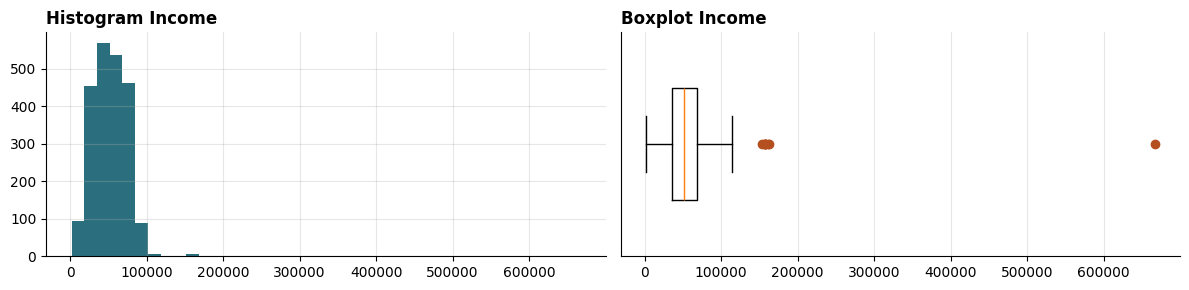

In [35]:
def lihat_sebaran(kolom):
    nilai = mentah[kolom].dropna()
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3))
    ax1.hist(nilai, bins=40, color=WARNA)
    ax1.set_title(f"Histogram {kolom}", loc="left", fontweight="bold")
    ax2.boxplot(nilai, vert=False, widths=0.5,
                flierprops={"markerfacecolor": WARNA_SOROT, "markeredgecolor": WARNA_SOROT})
    ax2.set_title(f"Boxplot {kolom}", loc="left", fontweight="bold")
    ax2.set_yticks([])
    plt.tight_layout()
    plt.show()

lihat_sebaran("Income")

Coba kolom-kolom lain. Ganti nama kolomnya, jalankan, lalu catat yang aneh.

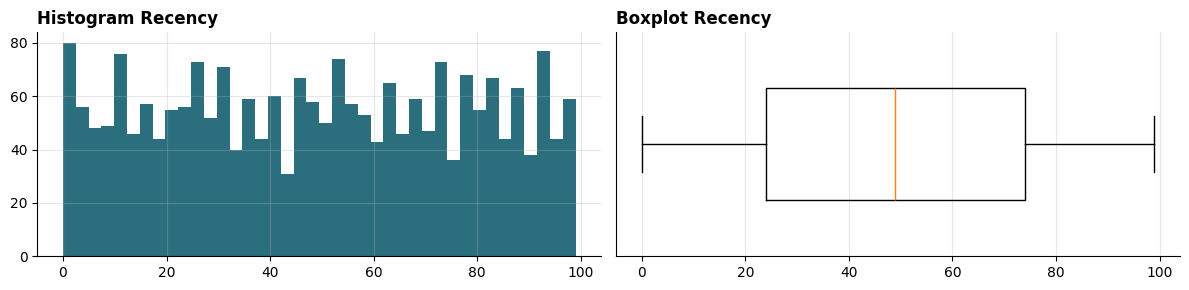

In [36]:
lihat_sebaran("Recency")   # ganti dengan kolom lain, misalnya "Year_Birth", "MntWines", atau "NumWebPurchases"

💬 **Amati:** titik-titik yang menyendiri di boxplot disebut **outlier**. Untuk tiap outlier yang kamu temukan, tanyakan: **mungkinkah nilai ini terjadi di dunia nyata?**

### 3.7 Duplikat

In [37]:
print("Baris yang persis sama:", mentah.duplicated().sum())

Baris yang persis sama: 0


💬 **Amati:** apakah hasil ini membuktikan bahwa tidak ada pelanggan yang tercatat dua kali? Ingat kembali hasil bagian 3.5: kolom mana yang **selalu** berbeda di setiap baris? Bagaimana jika satu pelanggan didaftarkan dua kali dan mendapat nomor yang berbeda?


---
## 4. Sebelum membersihkan: laporan awal dan log

Fungsi `audit()` merangkum kondisi tiap kolom dalam satu tabel. Fungsi ini kita pakai lagi di akhir untuk membandingkan.

In [42]:
def audit(data):
    return pd.DataFrame({
        "tipe": data.dtypes.astype(str),
        "kosong": data.isnull().sum(),
        "nilai_unik": data.nunique(),
        "contoh": data.iloc[0].astype(str),
    })

audit(mentah)

,tipe,kosong,nilai_unik,contoh
ID,int64,0,2240,5524
Year_Birth,int64,0,59,1957
Education,object,0,5,Graduation
Marital_Status,object,0,8,Single
Income,float64,24,1974,58138.0
Kidhome,int64,0,3,0
Teenhome,int64,0,3,0
Dt_Customer,object,0,663,04-09-2012
Recency,int64,0,100,58
MntWines,int64,0,776,635


Fungsi `laporan_profil()` menghitung ulang laporan anak magang, sehingga laporan yang sama bisa dibandingkan sebelum dan sesudah pembersihan. Umur dihitung terhadap tahun 2014, waktu cerita kita.

In [43]:
TAHUN_ACUAN = 2014

def laporan_profil(data):
    umur = TAHUN_ACUAN - data["Year_Birth"]
    return pd.Series({
        "jumlah_baris": len(data),
        "umur_termuda": umur.min(),
        "umur_tertua": umur.max(),
        "rata2_pendapatan": round(data["Income"].mean()),
        "median_pendapatan": round(data["Income"].median()),
        "pendapatan_kosong": data["Income"].isnull().sum(),
        "jenis_status_nikah": data["Marital_Status"].nunique(),
        "jenis_pendidikan": data["Education"].nunique(),
    })

laporan_awal = laporan_profil(mentah)
laporan_awal

,0
jumlah_baris,2240
umur_termuda,18
umur_tertua,121
rata2_pendapatan,52247
median_pendapatan,51382
pendapatan_kosong,24
jenis_status_nikah,8
jenis_pendidikan,5


In [60]:
df = mentah.copy()     # mulai bekerja pada salinan

---
## 5. Langkah 1 — Memperbaiki tipe data

Kembali ke temuan di bagian 3.1 dan 3.4. Lihat tipe kolom `Dt_Customer` (tanggal pelanggan mendaftar) dan contoh isinya.

In [61]:
print("Tipe:", df["Dt_Customer"].dtype)
df["Dt_Customer"].head()

Tipe: object


,Dt_Customer
0,04-09-2012
1,08-03-2014
2,21-08-2013
3,10-02-2014
4,19-01-2014


Selama masih berupa teks, kolom tanggal tidak bisa diurutkan dengan benar atau dihitung selisihnya.

Tanggal `04-09-2012` bisa berarti **4 September** atau **9 April**. 💬 Bagaimana cara memastikan formatnya dari isi data? (Petunjuk: lihat nilai lain di kolom ini. Adakah angka yang tidak mungkin menjadi bulan?)

Setelah formatnya diketahui, kita tulis secara eksplisit agar pandas tidak menebak.

In [62]:
df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"], format="%d-%m-%Y")

print("Tipe sekarang:", df["Dt_Customer"].dtype)
print("Pendaftaran pertama:", df["Dt_Customer"].min().date())
print("Pendaftaran terakhir:", df["Dt_Customer"].max().date())

Tipe sekarang: datetime64[ns]
Pendaftaran pertama: 2012-07-30
Pendaftaran terakhir: 2014-06-29


---
## 6. Langkah 2 — Membuang kolom yang tidak memberi informasi

Kolom yang isinya sama untuk semua baris tidak bisa membedakan satu pelanggan dengan yang lain.

In [63]:
kolom_konstan = [kolom for kolom in df.columns if df[kolom].nunique() == 1]

print("Kolom konstan:", kolom_konstan)

Kolom konstan: ['Z_CostContact', 'Z_Revenue']


In [64]:
df = df.drop(columns=kolom_konstan)
print("Jumlah kolom sekarang:", df.shape[1])

Jumlah kolom sekarang: 27


📝 Kolom ini dibuang dari data analisis, tetapi **nilainya kita catat** (lihat output di atas). Dokumentasi dataset tidak menjelaskan arti kedua kolom ini. Di Pertemuan 7 kita akan membicarakan biaya dan pendapatan kampanye, jadi catatan seperti ini bisa berguna nanti.

---
## 7. Langkah 3 — Duplikat

Kembali ke temuanmu di bagian 3.7. Cara paling umum adalah mencari baris yang **persis sama**.

In [65]:
print("Baris duplikat persis:", df.duplicated().sum())

Baris duplikat persis: 0


Nol, karena setiap baris punya `ID` yang berbeda sehingga dua baris tidak pernah persis sama. Jika satu pelanggan **didaftarkan dua kali** dan mendapat dua ID, cara ini tidak akan menemukannya. Kita cek ulang dengan mengabaikan kolom `ID`. Bandingkan dengan hasil percobaanmu di bagian 3.7.

In [66]:
kolom_tanpa_id = [kolom for kolom in df.columns if kolom != "ID"]

punya_kembaran = df.duplicated(subset=kolom_tanpa_id, keep=False)
print("Baris yang punya kembaran (selain ID):", punya_kembaran.sum())
print("Baris yang akan dibuang (salinan kedua dan seterusnya):", df.duplicated(subset=kolom_tanpa_id).sum())

Baris yang punya kembaran (selain ID): 358
Baris yang akan dibuang (salinan kedua dan seterusnya): 182


In [67]:
# Contoh satu pasang kembaran: semua kolom sama, hanya ID yang berbeda
contoh = df[punya_kembaran].sort_values(kolom_tanpa_id).head(2)
contoh

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Response
39,2968,1943,PhD,Divorced,48948.0,0,0,2013-02-01,53,437,8,206,160,49,42,2,7,10,5,6,1,0,0,0,0,0,1
894,8800,1943,PhD,Divorced,48948.0,0,0,2013-02-01,53,437,8,206,160,49,42,2,7,10,5,6,1,0,0,0,0,0,1


💬 **Diskusi:** dua orang berbeda bisa saja lahir di tahun yang sama dan punya pendapatan yang sama. Tetapi mungkinkah **semua 26 kolom lainnya** juga sama persis, sampai ke jumlah belanja tiap kategori dan jumlah kunjungan web? Apa penjelasan yang paling masuk akal?

Kita simpan salinan pertama dan membuang sisanya.

In [68]:
baris_sebelum = len(df)
df = df.drop_duplicates(subset=kolom_tanpa_id, keep="first")

print(baris_sebelum, "->", len(df))

2240 -> 2058


---
## 8. Langkah 4 — Kategori yang tidak konsisten atau tidak valid

In [69]:
df["Marital_Status"].value_counts()

,count
Marital_Status,
Married,795
Together,521
Single,448
Divorced,216
Widow,71
Alone,3
Absurd,2
YOLO,2


Bandingkan dengan catatanmu di bagian 3.4. Label mana yang wajar, dan mana yang perlu diputuskan? Keputusan kita:

| Label | Keputusan | Alasan |
|---|---|---|
| `Alone` | Ubah menjadi `Single` | Artinya sama, hanya beda kata |
| `Absurd`, `YOLO` | Buang barisnya | Bukan status pernikahan, dan jumlahnya hanya beberapa baris |

Di dunia kerja, idealnya kita **bertanya ke pemilik data** sebelum mengambil keputusan seperti ini.

In [70]:
df["Marital_Status"] = df["Marital_Status"].replace({"Alone": "Single"})

tidak_valid = df["Marital_Status"].isin(["Absurd", "YOLO"])
df[tidak_valid][["ID", "Year_Birth", "Marital_Status", "Income"]]

,ID,Year_Birth,Marital_Status,Income
2093,7734,1993,Absurd,79244.0
2134,4369,1957,Absurd,65487.0
2177,492,1973,YOLO,48432.0
2202,11133,1973,YOLO,48432.0


In [71]:
baris_sebelum = len(df)
df = df[~tidak_valid]

df["Marital_Status"].value_counts()

,count
Marital_Status,
Married,795
Together,521
Single,451
Divorced,216
Widow,71


Sekarang kolom pendidikan. Apakah kamu sudah mencari arti setiap label di bagian 3.4?

In [72]:
df["Education"].value_counts()

,count
Education,
Graduation,1029
PhD,448
Master,340
2n Cycle,188
Basic,49


`2n Cycle` (*second cycle*) adalah istilah sistem pendidikan Eropa untuk jenjang **setara magister**, jadi artinya sama dengan `Master`. Dua label untuk satu arti adalah contoh **inkonsistensi**. Kita satukan.

In [74]:
df["Education"] = df["Education"].replace({"2n Cycle": "Master"})

df["Education"].value_counts()

,count
Education,
Graduation,1029
Master,528
PhD,448
Basic,49


---
## 9. Langkah 5 — Nilai yang tidak masuk akal

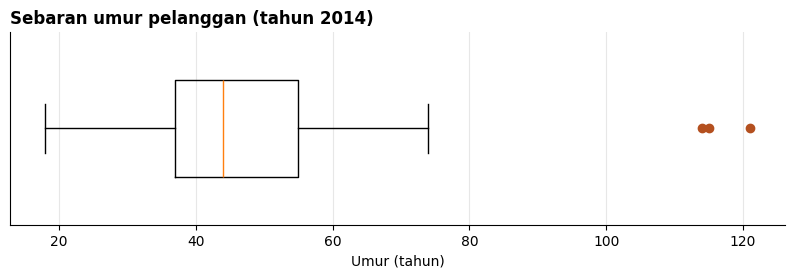

In [75]:
umur = TAHUN_ACUAN - df["Year_Birth"]

fig, ax = plt.subplots(figsize=(10, 2.5))
ax.boxplot(umur, vert=False, widths=0.5,
           flierprops={"markerfacecolor": WARNA_SOROT, "markeredgecolor": WARNA_SOROT})
ax.set_title("Sebaran umur pelanggan (tahun 2014)", loc="left", fontweight="bold")
ax.set_xlabel("Umur (tahun)")
ax.set_yticks([])
plt.show()

In [76]:
df[umur > 100][["ID", "Year_Birth", "Education", "Marital_Status", "Income"]]

,ID,Year_Birth,Education,Marital_Status,Income
192,7829,1900,Master,Divorced,36640.0
239,11004,1893,Master,Single,60182.0
339,1150,1899,PhD,Together,83532.0


💬 **Diskusi:** mungkinkah tahun lahir `1893`, `1899`, dan `1900` adalah salah ketik? Kalau iya, tahun lahir yang benar tidak bisa kita tebak dengan pasti.

Keputusan kita: **buang** baris-baris ini dan catat alasannya.

In [77]:
baris_sebelum = len(df)
df = df[(TAHUN_ACUAN - df["Year_Birth"]) <= 100]

print(baris_sebelum, "->", len(df))

2054 -> 2051


---
## 10. Langkah 6 — Outlier: kesalahan atau nilai nyata?

**Outlier** adalah nilai yang jauh berbeda dari sebagian besar data. Outlier **belum tentu salah**. Tugas kita: menemukannya, lalu menyelidikinya satu per satu.

### 10.1 Melihat dengan boxplot

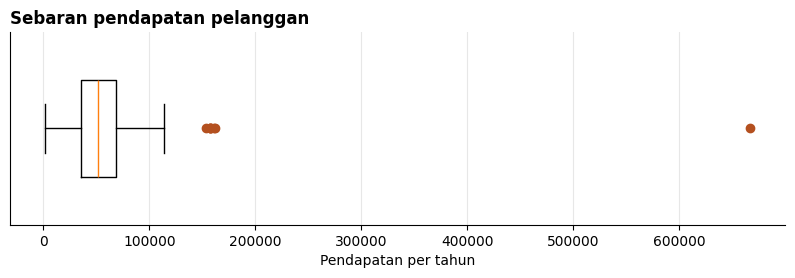

In [78]:
fig, ax = plt.subplots(figsize=(10, 2.5))
ax.boxplot(df["Income"].dropna(), vert=False, widths=0.5,
           flierprops={"markerfacecolor": WARNA_SOROT, "markeredgecolor": WARNA_SOROT})
ax.set_title("Sebaran pendapatan pelanggan", loc="left", fontweight="bold")
ax.set_xlabel("Pendapatan per tahun")
ax.set_yticks([])
plt.show()

Satu titik berada sangat jauh di kanan, sampai-sampai "kotak" boxplot-nya tergencet di kiri.

### 10.2 Metode IQR

Ini aturan yang dipakai boxplot:

- **IQR** (*interquartile range*) = Q3 − Q1, yaitu lebar 50% data di tengah.
- Nilai di bawah **Q1 − 1,5 × IQR** atau di atas **Q3 + 1,5 × IQR** dianggap outlier.

In [79]:
def batas_iqr(kolom):
    q1 = kolom.quantile(0.25)
    q3 = kolom.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

bawah, atas = batas_iqr(df["Income"])
print(f"Batas bawah: {bawah:,.0f}")
print(f"Batas atas : {atas:,.0f}")

outlier_iqr = (df["Income"] < bawah) | (df["Income"] > atas)
print("Jumlah outlier pendapatan (IQR):", outlier_iqr.sum())

Batas bawah: -14,140
Batas atas : 118,044
Jumlah outlier pendapatan (IQR): 8


### 10.3 Metode z-score

**Z-score** mengukur seberapa jauh sebuah nilai dari rata-rata, dalam satuan simpangan baku. Nilai dengan |z| > 3 biasanya dianggap outlier.

> z = (nilai − rata-rata) / simpangan baku

In [80]:
z = (df["Income"] - df["Income"].mean()) / df["Income"].std()
outlier_z = z.abs() > 3
print("Jumlah outlier pendapatan (z-score):", outlier_z.sum())

Jumlah outlier pendapatan (z-score): 8


### 10.4 Menyelidiki setiap outlier

Angka saja tidak cukup. Kita lihat siapa pelanggan-pelanggan ini dan bagaimana perilaku belanjanya.

In [81]:
kolom_cek = ["ID", "Income", "Education", "MntWines", "MntMeatProducts",
             "NumCatalogPurchases", "NumStorePurchases", "NumWebVisitsMonth"]

df[outlier_iqr][kolom_cek].sort_values("Income", ascending=False)

,ID,Income,Education,MntWines,MntMeatProducts,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth
2233,9432,666666.0,Graduation,9,18,1,3,6
617,1503,162397.0,PhD,85,16,0,1,1
687,1501,160803.0,PhD,55,1622,28,1,0
1300,5336,157733.0,Master,39,9,0,1,1
164,8475,157243.0,PhD,20,1582,22,0,0
1653,4931,157146.0,Graduation,1,1725,28,0,1
2132,11181,156924.0,PhD,2,2,0,0,0
655,5555,153924.0,Graduation,1,1,0,0,0


💬 **Diskusi:**

1. Satu nilai pendapatan berbeda sangat jauh dari yang lain dan angkanya berpola aneh. Menurutmu, nilai asli atau kesalahan input?
2. Bagaimana dengan pelanggan lain di tabel itu? Sebagian berbelanja banyak (misalnya lewat katalog), sebagian lagi hampir tidak berbelanja. Mana yang pendapatannya **konsisten** dengan belanjanya?
3. Mustahilkah orang berpendapatan tinggi jarang berbelanja di toko kita?

Keputusan kita:

| Kasus | Keputusan | Alasan |
|---|---|---|
| Pendapatan `666666` | Anggap kosong (`NaN`), lalu isi di langkah berikutnya | Pola angka janggal dan jauh di atas pendapatan tertinggi lainnya |
| Pendapatan tinggi lainnya | **Pertahankan**, tetapi catat | Tidak mustahil. Sebagian didukung belanja yang tinggi; yang belanjanya rendah juga masih mungkin terjadi |

In [82]:
jumlah_janggal = (df["Income"] == 666666).sum()
df.loc[df["Income"] == 666666, "Income"] = np.nan

print("Nilai yang dijadikan kosong:", jumlah_janggal)

Nilai yang dijadikan kosong: 1


### 10.5 Outlier pada kolom belanja

Kolom belanja (`Mnt...`) adalah jumlah uang yang dibelanjakan untuk tiap kategori produk selama dua tahun terakhir.

In [83]:
kolom_belanja = ["MntWines", "MntFruits", "MntMeatProducts", "MntFishProducts", "MntSweetProducts", "MntGoldProds"]

ringkasan = []
for kolom in kolom_belanja:
    bawah, atas = batas_iqr(df[kolom])
    ringkasan.append({
        "kolom": kolom,
        "batas_atas_iqr": round(atas),
        "nilai_maks": df[kolom].max(),
        "jumlah_outlier": int((df[kolom] > atas).sum()),
    })

pd.DataFrame(ringkasan)

,kolom,batas_atas_iqr,nilai_maks,jumlah_outlier
0,MntWines,1227,1493,33
1,MntFruits,81,199,205
2,MntMeatProducts,548,1725,175
3,MntFishProducts,121,259,198
4,MntSweetProducts,82,263,225
5,MntGoldProds,126,362,184


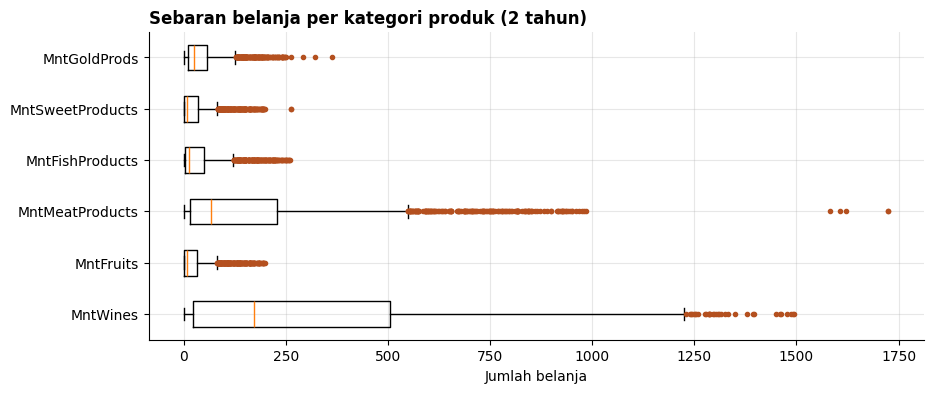

In [84]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.boxplot([df[k] for k in kolom_belanja], vert=False, widths=0.5,
           flierprops={"markerfacecolor": WARNA_SOROT, "markeredgecolor": WARNA_SOROT, "markersize": 3})
ax.set_yticks(range(1, len(kolom_belanja) + 1))
ax.set_yticklabels(kolom_belanja)
ax.set_title("Sebaran belanja per kategori produk (2 tahun)", loc="left", fontweight="bold")
ax.set_xlabel("Jumlah belanja")
plt.show()

💬 **Diskusi:** aturan IQR menandai ratusan pelanggan sebagai outlier belanja. Apakah mereka semua salah input?

Tidak. Dalam bisnis, wajar jika **sebagian kecil pelanggan berbelanja jauh lebih banyak** daripada pelanggan lain. Justru merekalah pelanggan paling berharga. Membuang mereka berarti membuang informasi penting.

> **Outlier ≠ kesalahan.** Hapus atau perbaiki hanya jika nilainya **mustahil** atau **terbukti salah**. Kalau nilainya nyata, pertahankan.

---
## 11. Langkah 7 — Nilai kosong

In [85]:
print("Pendapatan kosong:", df["Income"].isnull().sum())
df[df["Income"].isnull()][["ID", "Year_Birth", "Education", "Marital_Status", "Income"]].head()

Pendapatan kosong: 25


,ID,Year_Birth,Education,Marital_Status,Income
10,1994,1983,Graduation,Married,NaN
27,5255,1986,Graduation,Single,NaN
43,7281,1959,PhD,Single,NaN
48,7244,1951,Graduation,Single,NaN
58,8557,1982,Graduation,Single,NaN


Ada beberapa pilihan:

| Pilihan | Kelebihan | Kekurangan |
|---|---|---|
| Buang barisnya | Sederhana | Kehilangan pelanggan beserta data lainnya |
| Isi dengan **mean** (rata-rata) | Sederhana | Mudah terpengaruh nilai ekstrem |
| Isi dengan **median** (nilai tengah) | Tahan terhadap nilai ekstrem | Semua yang kosong diberi nilai sama |
| Isi berdasarkan kelompok | Lebih tepat sasaran | Sedikit lebih rumit |

Jumlah yang kosong sedikit, kita akan menggunakan variabel income sebagai variabel respon di pertemuan selanjutnya, sehingga baris yang memiliki nilai kosong pada variabel income di buang.

In [86]:
#buang baris yang memiliki variabel income kosong
df = df[~df["Income"].isnull()]
print("Jumlah baris sekarang:", len(df))

Jumlah baris sekarang: 2026


---
## 12. Laporan untuk manajer: sebelum vs sesudah

In [87]:
laporan_akhir = laporan_profil(df)

pd.DataFrame({"sebelum": laporan_awal, "sesudah": laporan_akhir})

,sebelum,sesudah
jumlah_baris,2240,2026
umur_termuda,18,18
umur_tertua,121,74
rata2_pendapatan,52247,52027
median_pendapatan,51382,51524
pendapatan_kosong,24,0
jenis_status_nikah,8,5
jenis_pendidikan,5,4


💬 **Diskusi:**

1. Berapa persen baris yang terbuang secara total? Apakah jumlahnya wajar?
2. Dari semua langkah, mana yang paling banyak mengubah jumlah pelanggan?
3. Bagian mana dari laporan yang paling menyesatkan jika dibawa ke direksi?

---
## 13. Menyimpan data bersih

Data bersih kita simpan sebagai file baru. File aslinya tetap utuh.

In [89]:
# simpan ke google drive
FILE_BERSIH = '/content/drive/MyDrive/UNIPA 2026/Meet 2/marketing_campaign_bersih.csv'
df.to_csv(FILE_BERSIH, index=False)

---
## 14. Latihan mandiri

**Latihan 1 — Konsistensi antar kolom.** Tampilkan data pelanggan dengan `ID` 5376. Bandingkan pendapatannya dengan belanja daging (`MntMeatProducts`) dan jumlah pembelian lewat katalog (`NumCatalogPurchases`). Masuk akal? Apa yang akan kamu lakukan, dan kenapa?
*Petunjuk:* `df[df["ID"] == 5376]`

In [ ]:
# Tulis jawaban Latihan 1 di sini

**Latihan 2 — Imputasi per kelompok.** Hitung median pendapatan untuk tiap jenjang pendidikan, memakai `income_sebelum_diisi`. Apakah mediannya sangat berbeda antar jenjang? Kalau iya, cara pengisian mana yang lebih adil?
*Petunjuk:* `income_sebelum_diisi.groupby(df["Education"]).median()`

In [ ]:
# Tulis jawaban Latihan 2 di sini

**Latihan 3 — Outlier kunjungan web.** Pakai fungsi `batas_iqr()` pada kolom `NumWebVisitsMonth`. Tampilkan pelanggan yang menjadi outlier beserta jumlah pembeliannya. Kesalahan atau nyata?

In [ ]:
# Tulis jawaban Latihan 3 di sini

**Latihan 4 — Satu langkah, dua cara.** Hitung ulang jumlah outlier pendapatan dengan IQR dan z-score **setelah** nilai `666666` dikosongkan. Apakah hasil kedua metode masih sama? Kenapa satu nilai ekstrem bisa mengubah hasil z-score?

In [ ]:
# Tulis jawaban Latihan 4 di sini

**Latihan 5 (tantangan) — Fungsi pembersihan.** Gabungkan semua langkah di notebook ini menjadi satu fungsi `bersihkan_data(data_mentah)` yang mengembalikan data bersih. Uji dengan `bersihkan_data(mentah).shape`. Hasilnya harus sama dengan `df.shape`. Fungsi seperti ini memudahkan kita membersihkan data baru dengan cara yang sama persis.

In [ ]:
# Tulis jawaban Latihan 5 di sini

---
## Rangkuman

| Dimensi | Masalah yang kita temukan | Tindakan |
|---|---|---|
| Format | File memakai pemisah tab | `sep="\t"` |
| Valid | Tanggal tersimpan sebagai teks | `pd.to_datetime()` dengan format eksplisit |
| — | Kolom yang isinya sama semua | Dibuang, nilainya dicatat |
| Unik | Pelanggan tercatat dua kali dengan ID berbeda | `drop_duplicates(subset=...)` |
| Konsisten | `Alone` vs `Single`, `2n Cycle` vs `Master` | `replace()` |
| Valid | Label `Absurd` dan `YOLO`, umur di atas 100 tahun | Barisnya dibuang |
| Valid | Pendapatan `666666` | Dijadikan kosong |
| Lengkap | Pendapatan kosong | Diisi median |

**Tiga kebiasaan yang dibawa pulang:**

1. Jangan pernah mengubah data asli; bekerja pada salinan.
2. Outlier bukan berarti salah. Selidiki dulu sebelum menghapus.
3. Catat setiap keputusan pembersihan beserta alasannya.

**Pertemuan berikutnya, Preprocessing Data 2:** data bersih ini kita siapkan untuk model, lewat encoding, scaling, dan membuat fitur baru seperti umur dan total belanja.